![](img/banner.png)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 120

# Clustering Validation

**Mahmood Amintoosi, Fall 2026**

Computer Science Dept, Ferdowsi University of Mashhad

This page follows chapter 17 of {cite}`zaki2020data`,
[Clustering Validation](https://www.cs.rpi.edu/~zaki/DMML/slides/pdf/ychap17.pdf).

## Introduction to Clustering Validation

Clustering validation assesses the quality of a clustering. Every algorithm returns *some*
partition of the data; the question is whether that partition is any good, and how two
candidate partitions can be compared. The measures fall into three families:

1. **External measures**: use external information, the ground-truth labels.
2. **Internal measures**: use only the data and the clustering result.
3. **Relative measures**: compare two clusterings of the same data with each other,
   without any ground truth.

**Learning objectives.** By the end you should be able to

1. build the contingency table of a clustering against the ground truth, and read it;
2. compute and interpret purity, precision/recall/F, maximum matching, Jaccard, Rand, ARI
   and NMI, and say what each one ignores;
3. explain why accuracy cannot be used on cluster labels;
4. use internal measures (silhouette, SSE, gap) and say why none of them identifies the
   "true" number of clusters;
5. see the maximum-matching score as an assignment problem.

#### Notation

Zaki writes $r$ for the number of clusters and $k$ for the number of ground-truth classes.
This page keeps those letters, so that the formulas match the book; note that the
k-means pages of this course use $k$ for the number of *clusters*. In every formula below
$n_{ij}$ counts the points of cluster $C_i$ that belong to class $T_j$, and $n$ is the
number of points.

## External Measures

External measures assume that the correct or  ground-truth clustering is known *a priori*, which  is used to evaluate a given clustering.  

Let $\mathbf{D} = \{\mathbf{x}_i\}_{i=1}^n$ be a dataset consisting of $n$ points in a  $d$-dimensional space, partitioned into $k$ clusters. Let $y_i \in  
\left\{ 1, 2,\ldots , k \right\}$ denote the ground-truth cluster  membership or label information for each point.  

The ground-truth clustering is given as:  

$$
\mathbf{T} = \left\{ T_1, T_2, \ldots, T_k \right\}
$$

where the cluster $T_{j}$ consists of all the points with label $j$, i.e.,  

$$
T_{j} = \left\{ \mathbf{x}_i \in \mathbf{D} \mid y_i = j \right\}
$$

We refer to $\mathbf{T}$ as the ground-truth *partitioning*, and to each $T_i$ as a *partition* (class).  

Let $\mathbf{C} = \{C_1, \ldots, C_r\}$ denote a clustering of the same dataset into $r$  clusters, obtained via some clustering algorithm, and let $\hat{y}_i \in  
\left\{ 1, 2, \ldots, r \right\}$ denote the cluster label for $\mathbf{x}_i$.  

External evaluation measures try to capture the extent to which points from the same partition appear in the  same cluster, and the extent to which points from different partitions  are grouped in different clusters.

All of the external measures rely on the $r \times k$  **contingency table** $\mathbf{N}$ that is induced by a clustering $\mathbf{C}$ and the ground-truth partitioning $\mathbf{T}$, defined as follows:  

$$
\mathbf{N}(i,j) = n_{ij}  = \left| C_i \cap T_{j} \right|
$$

The count $n_{ij}$ denotes the number of points that are common to cluster $C_i$ and ground-truth partition $T_{j}$.  

Let $n_{i} = |C_i|$ denote the number of points in cluster $C_i$, and let $m_{j} = |T_{j}|$ denote the number of points in partition  $T_{j}$.  The contingency table can be computed from $\mathbf{T}$ and $\mathbf{C}$ in $O(n)$ time by examining the partition and cluster labels, $y_i$ and  $\hat{y}_i$, for each point $\mathbf{x}_i \in \mathbf{D}$ and incrementing the corresponding count $n_{\hat{y}_i,\,y_i}$ — the first index is the cluster label, the second the class label, so that rows of $\mathbf{N}$ are clusters and columns are classes. 

In [2]:
import pandas as pd

def display_contingency_table_pandas(table, class_names=None, cluster_names=None):
    r, k = table.shape
    if class_names is None:
        class_names = [f"Class {j}" for j in range(k)]
    if cluster_names is None:
        subscript = "₀₁₂₃₄₅₆₇₈₉"
        cluster_names = [f"C{subscript[i]}" for i in range(r)]

    df = pd.DataFrame(table, index=cluster_names, columns=class_names)
    display(df.style
              .set_properties(**{'text-align': 'center'})
              .set_table_styles([
                  {'selector': 'th',
                   'props': [('text-align', 'center'),
                             ('background-color', '#f2f2f2'),
                             ('border', '1px solid #ccc')]},
                  {'selector': 'td',
                   'props': [('border', '1px solid #ccc')]},
              ]))

In [3]:
import numpy as np


def compute_contingency_table(cluster_labels, true_labels):
    """Contingency table of a clustering against the ground truth.

    Returns an ``(r, k)`` integer matrix: rows index clusters, columns index classes,
    so ``table[i, j]`` is the number of points of cluster ``i`` in class ``j``.
    """
    unique_classes, class_map = np.unique(true_labels, return_inverse=True)
    unique_clusters, cluster_map = np.unique(cluster_labels, return_inverse=True)

    table = np.zeros((len(unique_clusters), len(unique_classes)), dtype=int)
    np.add.at(table, (cluster_map, class_map), 1)
    return table

### A first reference point: a perfect clustering

Before looking at anything that goes wrong, we need a baseline. The table
below is obtained when every cluster matches exactly one ground-truth class.
The contingency matrix is **diagonal**: every off-diagonal entry is zero.

This is the only case in which the "ideal" value of any reasonable external
measure is reached (1 for purity, NMI and ARI). Every other example on this
page should be compared against this baseline.

In [4]:
# Example A — perfect clustering
true_labels    = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])

table = compute_contingency_table(cluster_labels, true_labels)
display_contingency_table_pandas(table)

,Class 0,Class 1,Class 2
C₀,3,0,0
C₁,0,3,0
C₂,0,0,3


### A good clustering with a small, symmetric mistake

Most realistic clusterings are almost right. Here, `C₀` is still perfectly
pure, but `C₁` and `C₂` have **swapped one point each**: one point from class
`T₁` landed in `C₂` and one from `T₂` landed in `C₁`.

The table is almost diagonal, so purity, NMI and ARI will all be close to but
slightly below 1. This is the typical "slightly imperfect" case that most
practical algorithms produce.

In [5]:
# Example B — almost perfect, one swap
true_labels    = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 0, 0, 1, 1, 2, 2, 2, 1])

table = compute_contingency_table(cluster_labels, true_labels)
display_contingency_table_pandas(table)

,Class 0,Class 1,Class 2
C₀,3,0,0
C₁,0,2,1
C₂,0,1,2


### Cluster ids are arbitrary labels, not orderings

The partition below is **exactly the same** as the one in Example B; only the
ids of the clusters have been permuted. `C₁` in this example is what `C₂` was
before, and vice versa.

The table is the same as B with its rows rearranged — and every external
measure gives the same numerical value. This is the reason all external
measures must be **invariant to permutations of the cluster ids**: the numbers
`0`, `1`, `2` returned by `KMeans.labels_` are just names, not a ranking.

In [6]:
# Example C — same partition as B, cluster ids relabelled
true_labels    = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
cluster_labels = np.array([1, 1, 1, 2, 2, 0, 0, 0, 2])

table = compute_contingency_table(cluster_labels, true_labels)
display_contingency_table_pandas(table)

,Class 0,Class 1,Class 2
C₀,0,1,2
C₁,3,0,0
C₂,0,2,1


### A weak clustering with symmetric spread

Now the clustering is not close to the ground truth at all. Every cluster
contains points from two different classes, and every class is split across
two clusters. The table has several non-zero entries per row and per column,
but no row or column is "pure".

Purity will be around 0.5, NMI and ARI will be clearly below 1. Notice that
there is still **some** signal: the diagonal entries are not zero, so the
clustering is not random — it is simply weak.

In [7]:
# Example D — weak clustering, scattered table
true_labels    = np.array([0, 0, 1, 1, 2, 2])
cluster_labels = np.array([0, 1, 1, 2, 2, 0])

table = compute_contingency_table(cluster_labels, true_labels)
display_contingency_table_pandas(table)

,Class 0,Class 1,Class 2
C₀,1,0,1
C₁,1,1,0
C₂,0,1,1


### A deceptive case: a perfectly uniform table

This example has a contingency table in which **every entry is exactly equal**.
Every cluster contains one point from each class, and every class is spread
evenly across all clusters.

This is the most instructive case on the page. The table looks neat and
regular, yet it carries **no information**: knowing which cluster a point was
assigned to tells us nothing about its true class.

Purity is exactly `1/3`, and NMI and ARI are exactly 0 — the same values a
completely random assignment would produce. Regularity of the table is not the
same thing as usefulness of the clustering.

In [8]:
# Example E — deceptive, uniform contingency table
true_labels    = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 1, 2, 1, 2, 0, 2, 0, 1])

table = compute_contingency_table(cluster_labels, true_labels)
display_contingency_table_pandas(table)

,Class 0,Class 1,Class 2
C₀,1,1,1
C₁,1,1,1
C₂,1,1,1


### When the number of clusters differs from the number of classes

All examples so far had $k = r$: as many clusters as ground-truth classes.
But K-means is run with a fixed `K` that the user chooses, and there is no
guarantee that `K` matches the number of true classes.

In the example below, the ground truth has **three** classes but the algorithm
produced **four** clusters — it has *over-segmented* one of the classes into
two pieces. The contingency table is therefore not square, and no simple
"accuracy" can be computed: there is no one-to-one correspondence between
cluster ids and class ids.

Purity is still computable and still meaningful: it asks, for each cluster,
how pure it is, and then averages. But an over-segmented clustering gets a
suspiciously high purity, because small pure clusters are easy to form. NMI
and ARI penalise this properly, which is exactly why they are preferred in
practice when `K` is not known in advance.

In [9]:
# Example F — k = 4 clusters vs r = 3 classes (over-segmentation)
# The 3 points of class T₀ are split across two clusters: C₀ and C₃.
true_labels    = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 0, 3, 1, 1, 1, 2, 2, 2])

table = compute_contingency_table(cluster_labels, true_labels)
display_contingency_table_pandas(table)

,Class 0,Class 1,Class 2
C₀,2,0,0
C₁,0,3,0
C₂,0,0,3
C₃,1,0,0


### The opposite case: too few clusters

Here the situation is reversed: the algorithm was run with $K = 2$, but there
are **three** true classes. Two of them have been merged into a single cluster.

The contingency table is now a $2 \times 3$ matrix, with one row containing
points from two different classes. Purity drops immediately, because that row
has two non-zero entries of comparable size. Under-segmentation is much harder
to hide than over-segmentation.

In [10]:
# Example G — k = 2 clusters vs r = 3 classes (under-segmentation)
# Classes T₀ and T₁ have been merged into a single cluster C₀.
true_labels    = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
cluster_labels = np.array([0, 0, 0, 0, 0, 0, 1, 1, 1])

table = compute_contingency_table(cluster_labels, true_labels)
display_contingency_table_pandas(table)

,Class 0,Class 1,Class 2
C₀,3,3,0
C₁,0,0,3


## Efficient Contingency Table Computation with `np.add.at`

When implementing clustering validation metrics, constructing a **contingency table** is a key step. One efficient way to do this in **NumPy** is using `np.add.at`. This method ensures **correct accumulation of counts** when duplicate indices are present.

### Why `np.add.at`?
Unlike simple **indexed incrementation**, such as:
```python
contingency_table[cluster_map, class_map] += 1
```
NumPy’s **fancy indexing** creates a temporary copy, meaning updates to repeated indices may not accumulate correctly. Instead, `np.add.at` ensures in-place modifications:

```python
np.add.at(contingency_table, (cluster_map, class_map), 1)
```

### Example: Difference Between Direct Indexing and `np.add.at`
Here’s an example illustrating how `np.add.at` correctly handles duplicate indices while direct indexing may fail:

In [11]:
import numpy as np

def compute_contingency_table_direct(cluster_labels, true_labels):
    """Same table, built with direct indexed incrementation."""
    unique_classes, class_map = np.unique(true_labels, return_inverse=True)
    unique_clusters, cluster_map = np.unique(cluster_labels, return_inverse=True)

    table = np.zeros((len(unique_clusters), len(unique_classes)), dtype=int)
    table[cluster_map, class_map] += 1  # a temporary copy is written back: duplicates are lost
    return table

In [12]:
import numpy as np

true_labels    = np.array([0, 0, 1, 1, 1, 2, 2, 2, 2])
cluster_labels = np.array([0, 1, 1, 1, 1, 2, 2, 2, 2])

contingency_table_at = compute_contingency_table(cluster_labels, true_labels)
contingency_table_direct = compute_contingency_table_direct(cluster_labels, true_labels)

print("Using direct indexing:")
display_contingency_table_pandas(contingency_table_direct)

print("\nUsing np.add.at:")
display_contingency_table_pandas(contingency_table_at)

Using direct indexing:


,Class 0,Class 1,Class 2
C₀,1,0,0
C₁,1,1,0
C₂,0,0,1



Using np.add.at:


,Class 0,Class 1,Class 2
C₀,1,0,0
C₁,1,3,0
C₂,0,0,4


### 1. Purity

Purity measures how "pure" each cluster is by the fraction of points from the majority class:

$$
\text{purity} = \frac{1}{n}\sum_{i=1}^r \max_{j=1}^k \{n_{ij}\}
$$

Where:
- $ n $ = total number of points
- $ r $ = number of clusters
- $ k $ = number of true classes
- $ n_{ij} $ = number of points in cluster $ i $ from class $ j $

In [13]:
def purity_score(cluster_labels, true_labels):
    contingency_matrix = compute_contingency_table(cluster_labels, true_labels)
    return np.sum(np.amax(contingency_matrix, axis=1)) / np.sum(contingency_matrix)

Let's consider an example where we achieve **high purity**, ensuring our clustering is well-aligned with the ground-truth partitioning.

### **Example Data**
Suppose we have the following clustering and ground-truth labels:
```python
true_labels    = np.array([0, 0, 1, 1, 1, 2])
cluster_labels = np.array([0, 0, 1, 1, 2, 2])
```
Here, each cluster aligns better with a single true class.

### **Compute Contingency Table**
Using the `compute_contingency_table` function, we obtain:

|   | Class 0 | Class 1 | Class 2 |
|---|--------|--------|--------|
| C₀ | 2 | 0 | 0 |
| C₁ | 0 | 2 | 0 |
| C₂ | 0 | 1 | 1 |

### **Middle Computations**
**Step 1:** Find the max of each row:
- `max(C₀) = 2`  
- `max(C₁) = 2`  
- `max(C₂) = 1`  

**Step 2:** Sum the max values:
$ \sum \max(n_{ij}) = 2 + 2 + 1 = 5 $

**Step 3:** Compute purity:
$
\text{Purity} = \frac{\sum \max(n_{ij})}{\sum n_{ij}} = \frac{5}{6} \approx 0.833
$

In [14]:
true_labels = np.array([0, 0, 1, 1, 1, 2])
cluster_labels = np.array([0, 0, 1, 1, 2, 2])

score = purity_score(cluster_labels, true_labels)
print(f"Purity Score: {score:.3f}")  # Expected output: 0.833

Purity Score: 0.833


**purity is invariant to cluster labels**, meaning that relabeling clusters doesn't change the score as long as the assignment itself remains consistent.

Let's take the previous clustering but **shift the cluster labels** (e.g., renaming clusters **C₀ $\rightarrow$ C₂**, **C₁ $\rightarrow$ C₀**, **C₂ $\rightarrow$ C₁**):

In [15]:
import numpy as np

# Original clustering labels
true_labels            = np.array([0, 0, 1, 1, 1, 2])
cluster_labels         = np.array([0, 0, 1, 1, 2, 2])
shifted_cluster_labels = np.array([2, 2, 0, 0, 1, 1]) # Shifted cluster labels (mapping: 0 → 2, 1 → 0, 2 → 1)

# Compute purity scores for both cases
original_purity = purity_score(cluster_labels, true_labels)
shifted_purity = purity_score(shifted_cluster_labels, true_labels)

print(f"Original Purity: {original_purity:.3f}")  # Expected output: 0.833
print(f"Shifted Labels Purity: {shifted_purity:.3f}")  # Expected output: 0.833 (same!)

Original Purity: 0.833
Shifted Labels Purity: 0.833


**Why Does Purity Stay the Same?**
- The **mapping between clusters and ground-truth partitions hasn't changed**, only their labels.
- Since purity only depends on **how well clusters match ground-truth partitions**, renaming clusters **doesn't affect** purity calculations.

### 2. Precision, Recall and F-measure

For each cluster $ C_i $:

- **Precision**: Fraction of points in cluster from majority class
- **Recall**: Fraction of points from class found in cluster

![](img/Precisionrecall.png)

### Precision  
Given cluster $C_i$, let $j_i$ denote the partition that contains the maximum number
of points from $C_i$,

$$
j_i = \arg\max_{j=1}^{k} \left\{ n_{ij} \right\}
$$

that is, the index of the largest entry in row $i$ of the contingency table. 
The precision of a cluster $C_i$ is the same as its purity:

$$
\mathit{prec}_i = \frac{1}{n_{i}}\max_{j=1}^k \left\{ n_{ij} \right\} =
\frac{n_{ij_i}}{n_i}
$$

### Recall  
The recall of cluster $C_i$ is defined as:

$$
\mathit{recall}_i = \frac{n_{ij_i}}{|\mathbf{T}_{j_i}|} =\frac{n_{ij_i}}{m_{j_i}}
$$

where $m_{j_i} = |\mathbf{T}_{j_i}|$.  

### F-Measure  
The F-measure is the harmonic mean of the precision and recall values for each $C_i$:

$$
F_i = \frac{2}{\frac{1}{\mathit{prec}_i} + \frac{1}{\mathit{recall}_i}} =
\frac{2 \cdot \mathit{prec}_i \cdot \mathit{recall}_i}{\mathit{prec}_i + \mathit{recall}_i} =
\frac{2 \; n_{ij_i}}{n_{i} + m_{j_i}}
$$

The **F-measure** for the clustering $\mathbf{C}$ is the mean of clusterwise F-measure values:

$$
F = \frac{1}{r} \sum_{i=1}^r F_i
$$

### 3. Maximum Matching

Finds the best matching between clusters and true classes to maximize overlap:

$$
\text{match} = \frac{1}{n}\max_M \sum_{(i,j)\in M} n_{ij}
$$

Where $ M $ is a matching between clusters and classes.

**Maximum weight matching** (following {cite}`zaki2020data`)


Let $G$ be a bipartite graph over the vertex set $V = \mathbf{C} \cup \mathbf{T}$, and let the edge set be $E = \{ (C_i, T_{j}) \}$ with  edge weights $w(C_i,T_{j}) = n_{ij}$.  A **matching** $M$ in $G$ is a subset of $E$, such that the edges in $M$ are pairwise nonadjacent, meaning they do not have a common vertex.

The maximum weight matching in $G$ is given as:

$$
\mathit{match} = \max_{M} \left\{ \frac{w(M)}{n} \right\}
$$

where $w(M)$ is the sum of all edge weights in matching $M$,  given as $w(M) = \sum_{e \in M} w(e)$.  

### Maximum Matching Example (Bipartite Graph Interpretation)

**Scenario**: Imagine we have clustered 10 fruits into 3 clusters, and we know their true categories (ground truth):

```
True Categories (T₁=apples, T₂=oranges, T₃=bananas):
T₁: apple1, apple2, apple3, apple4
T₂: orange1, orange2, orange3
T₃: banana1, banana2, banana3

Cluster Assignments (C₁, C₂, C₃):
C₁: [apple1, apple2, banana1]
C₂: [orange1, orange2, apple3] 
C₃: [banana2, banana3, orange3, apple4]

```

### Contingency Table

|   | Apples (T₁) | Oranges (T₂) | Bananas (T₃) | Total (nᵢ) |
|---|------------|-------------|-------------|-------------|
| C₁ (apple1, apple2, banana1) | 2 | 0 | 1 | 3 |
| C₂ (orange1, orange2, apple3) | 1 | 2 | 0 | 3 |
| C₃ (banana2, banana3, orange3, apple4) | 1 | 1 | 2 | 4 |
| **Total (mⱼ)** | 4 | 3 | 3 | **n = 10** |


**Step 1: Build the Bipartite Graph**

We create edges between clusters and categories with weights equal to their overlap:

```
Clusters       Categories
   C₁ ------------- T₁ (weight=2: apple1,apple2)
      \------------ T₃ (weight=1: banana1)
   C₂ ------------- T₁ (weight=1: apple3)
      \------------ T₂ (weight=2: orange1,orange2)
   C₃ ------------- T₁ (weight=1: apple4)
      \------------ T₂ (weight=1: orange3)
      \------------ T₃ (weight=2: banana2,banana3)
```

**Step 2: Find Maximum Weight Matching**

We want to match each cluster to at most one category (and vice versa) to maximize total weight:

Possible matching options:
1. Match C₁-T₁ (2), C₂-T₂ (2), C₃-T₃ (2) $\rightarrow$ Total weight = 6
2. Match C₁-T₃ (1), C₂-T₂ (2), C₃-T₁ (1) $\rightarrow$ Total weight = 4

The first option gives us the maximum weight matching.

**Step 3: Calculate Maximum Matching Score**

$$
\text{match} = \frac{\text{Total matched weight}}{n} = \frac{2+2+2}{10} = 0.6
$$

In [16]:
import numpy as np
from scipy.optimize import linear_sum_assignment

# Define contingency table
contingency = np.array([
    [2, 0, 1],  # C₁: 2 apples, 0 oranges, 1 banana
    [1, 2, 0],  # C₂: 1 apple, 2 oranges, 0 bananas
    [1, 1, 2]   # C₃: 1 apple, 1 orange, 2 bananas
])

# Find optimal matching
row_ind, col_ind = linear_sum_assignment(contingency, maximize=True)

# Perform indexing correctly
max_weight = contingency[row_ind, col_ind].sum()

print(f"Optimal matching: {list(zip(row_ind, col_ind))}")
print(f"Max weight: {max_weight}")

# Optimal matching: [(0, 0), (1, 1), (2, 2)]  # C₁-T₁, C₂-T₂, C₃-T₃

Optimal matching: [(np.int64(0), np.int64(0)), (np.int64(1), np.int64(1)), (np.int64(2), np.int64(2))]
Max weight: 6


### Example 17.1: Good vs Bad Clustering on Iris Data

Let's examine two different clusterings of the Iris dataset using principal components:

#### Good Clustering Results:

![](img/Zaki-Chap17-Good-Clustering.png)

### Contingency Table

|   | iris-setosa | iris-versicolor | iris-virginica | Total (n_i) |
|---|------------|----------------|---------------|-------------|
| C₁ (squares)  | 0  | 47  | 14  | 61  |
| C₂ (circles)  | 50 | 0   | 0   | 50  |
| C₃ (triangles) | 0  | 3   | 36  | 39  |
| **Total (m_j)** | 50 | 50  | 50  | **n = 150** |

**Purity:** 0.887  
**Match:** 0.887  
**F:** 0.885  

#### Bad Clustering Results:

![](img/Zaki-Chap17-Bad-Clustering.png)

### Contingency Table

|   | iris-setosa | iris-versicolor | iris-virginica | Total (n_i) |
|---|------------|----------------|---------------|-------------|
| C₁ (squares)  | 30  | 0   | 0   | 30  |
| C₂ (circles)  | 20  | 4   | 0   | 24  |
| C₃ (triangles) | 0  | 46  | 50  | 96  |
| **Total (m_j)** | 50  | 50  | 50  | **n = 150** |

**Purity:** 0.667  
**Match:** 0.560  
**F:** 0.658

The row maxima are $30+20+50=100$, hence purity $=100/150=0.667$. The maximum matching
pairs $C_1$–setosa (30), $C_2$–versicolor (4) and $C_3$–virginica (50), so
match $=84/150=0.560$. Purity and match differ here because purity may assign two clusters
to the same class while the matching may not.

### 4. Pairwise Measures


First, let's define some key quantities used in external measures:

- **TP (True Positives)**: Pairs in same cluster and same true partition
- **FP (False Positives)**: Pairs in same cluster but different partitions
- **TN (True Negatives)**: Pairs in different clusters and different partitions
- **FN (False Negatives)**: Pairs in different clusters but same partition

Given clustering $\mathbf{C}$ and ground-truth partitioning $\mathbf{T}$, let  $\mathbf{x}_i, \mathbf{x}_{j} \in \mathbf{D}$ be any two points, with $i \ne j$.  Let $y_i$ denote the true partition label and let $\hat{y}_i$ denote the cluster label for  point $\mathbf{x}_i$.  

If both $\mathbf{x}_i$ and $\mathbf{x}_{j}$ belong to the same cluster, that is, $\hat{y}_i =  
\hat{y}_{j}$, we call it a *positive* event, and if they do not belong to the same cluster, that is, $\hat{y}_i \ne \hat{y}_{j}$, we call that a *negative* event.  Depending on whether there is agreement between the cluster labels and  partition labels, there are four possibilities to consider:  

 **True Positives (TP)**  
$\mathbf{x}_i$ and $\mathbf{x}_{j}$ belong to the same  partition in $\mathbf{T}$, and they are also in the same cluster in $\mathbf{C}$. The number of true positive pairs is given as:  

$$
\mathit{TP} = \bigl|\{(\mathbf{x}_i, \mathbf{x}_{j}):\; y_i = y_{j}
\text{ and } \hat{y}_i = \hat{y}_{j} \}\bigr|
$$

 **False Negatives (FN)**  
$\mathbf{x}_i$ and $\mathbf{x}_{j}$ belong to the same partition in $\mathbf{T}$, but they do not belong to the same cluster in $\mathbf{C}$.  The number of false negative pairs is given as:  

$$
\mathit{FN} = \bigl|\{(\mathbf{x}_i, \mathbf{x}_{j}):\; y_i = y_{j}
\text{ and } \hat{y}_i \ne \hat{y}_{j} \}\bigr|
$$

 

 **False Positives (FP)**  
$\mathbf{x}_i$ and $\mathbf{x}_{j}$ do not belong to the  same partition in $\mathbf{T}$, but they do belong to the same cluster in $\mathbf{C}$. The number of false positive pairs is given as:  

$$
\mathit{FP} = \bigl|\{(\mathbf{x}_i, \mathbf{x}_{j}):\; y_i \ne y_{j}
\text{ and } \hat{y}_i = \hat{y}_{j} \}\bigr|
$$

 **True Negatives (TN)**  
$\mathbf{x}_i$ and $\mathbf{x}_{j}$ neither belong to  the same partition in $\mathbf{T}$, nor do they belong to the same cluster in $\mathbf{C}$. The number of such true negative pairs is given as:  

$$
\mathit{TN} = \bigl|\{(\mathbf{x}_i, \mathbf{x}_{j}):\; y_i \ne y_{j}
\text{ and } \hat{y}_i \ne \hat{y}_{j} \}\bigr|
$$

### A pairwise view of the external measures

Both Jaccard and Rand look at the clustering problem in a different way from
the contingency table: instead of comparing cluster ids to class ids, they ask
a question about every **pair of points**.

For a pair `(i, j)` we can ask two yes/no questions:

* are `i` and `j` in the same ground-truth class?
* are `i` and `j` in the same cluster?

Four cases are possible:

|                        | same cluster   | different cluster |
|:----------------------:|:--------------:|:-----------------:|
| **same class**         | TP (True Positive)  | FN (False Negative) |
| **different class**    | FP (False Positive) | TN (True Negative)  |

* **TP** — a pair that is together in the ground truth **and** together in the clustering.
* **TN** — a pair that is apart in the ground truth **and** apart in the clustering.
* **FP** — a pair that is apart in the ground truth but **merged** by the clustering.
* **FN** — a pair that is together in the ground truth but **split** by the clustering.

Everything that follows is a different way of combining these four counts.

#### Jaccard Coefficient
$$
\text{Jaccard} = \frac{TP}{TP + FN + FP}
$$

#### Rand Index
$$
\text{Rand} = \frac{TP + TN}{TP + FN + FP + TN} = \frac{TP + TN}{\binom{n}{2}}
$$

#### What Jaccard actually measures

$$
\text{Jaccard} = \frac{TP}{TP + FN + FP}
$$

Jaccard only looks at the **positive pairs** — those that are together in at
least one of the two partitions — and asks what fraction of them are together
in **both**. The count `TN` is completely ignored.

Because `TN` grows very fast as the number of clusters increases, ignoring it
is a deliberate choice: Jaccard stays meaningful even when the number of
clusters is large or when the two partitions do not have the same number of
groups. It is the most robust of the pairwise measures in that respect.

#### What Rand actually measures

$$
\text{Rand} = \frac{TP + TN}{TP + FN + FP + TN}
             = \frac{TP + TN}{\binom{n}{2}}
$$

Rand counts **both kinds of agreement**: pairs that are together in both
partitions (`TP`), and pairs that are apart in both partitions (`TN`). The
denominator is the total number of pairs, so Rand asks: *in what fraction of
all possible pairs do the two partitions agree?*

Rand looks superficially similar to accuracy in classification, but the two
measures are **not** the same thing. The next two subsections explain why.

#### Rand is not accuracy

At first glance, Rand looks like the clustering analogue of accuracy: both
divide the number of "correct decisions" by the total number of decisions,
both lie in `[0, 1]`, and both are often described informally as "the
percentage of agreement". The similarity, however, is only superficial.
Accuracy and Rand differ in three fundamental respects.

**1. The unit being counted is different.**

Accuracy asks a question about every **sample**: is the predicted label equal
to the true label? Rand asks a question about every **pair of points**: are
these two points on the same side of both partitions? A clustering of `n`
points contains `n(n-1)/2` pairs, so Rand makes a number of decisions that
grows **quadratically** with the size of the dataset. These are not the same
kind of decisions at all.

**2. There is no one-to-one mapping between cluster ids and class ids.**

In classification, each class has a **meaningful, unique label**. In
clustering, the ids produced by `KMeans.labels_` are arbitrary: cluster `0` in
one run may be cluster `1` in the next. You cannot compute accuracy on cluster
ids directly, because there is no ground-truth label to compare them against.
Rand sidesteps the problem entirely: it never mentions ids, only the
same/different relation between pairs, which is invariant to relabelling.

**3. Rand is defined even when `k ≠ r`.**

Accuracy presupposes a fixed number of classes. Rand does not: it works
whether the algorithm produced more clusters than there are classes
(over-segmentation) or fewer (under-segmentation). This is why Rand remains
computable on the examples where accuracy simply has no meaning.

**The one weakness they share.** Accuracy is misleading on imbalanced data:
predicting the majority class everywhere gives a high score while learning
nothing. Rand has the analogous weakness for clusterings with many groups: as
`k` grows, `TN` dominates the numerator and Rand approaches `1` even for a
random labelling. The two measures fail in different ways, but neither is
trustworthy on its own when the problem is unbalanced.

#### Adjusted Rand Index (ARI)

Because `TN` grows very fast as `k` increases, Rand is **not corrected for
chance**: a completely random labelling of the same `n` points with the same
`k` clusters already has a high expected Rand value. A useful measure should
give `0` to such a random labelling and `1` only to a perfect one.

The **Adjusted Rand Index** does exactly that. It subtracts the value that
Rand is *expected* to take under random labelling, and divides by the maximum
possible correction:

$$
\text{ARI} =
\frac{\text{Rand} - \mathbb{E}[\text{Rand}]}
     {\max(\text{Rand}) - \mathbb{E}[\text{Rand}]}
$$

The expected value is computed from the row and column sums of the
contingency table (the sizes of the clusters and the sizes of the classes), so
it does not assume anything about the data.

The interpretation of ARI is:

* `ARI = 1` — the two partitions are identical (up to relabelling).
* `ARI = 0` — the clustering is no better than a random labelling with the
  same cluster sizes.
* `ARI < 0` — the clustering is **worse** than random, which can genuinely
  happen when the algorithm systematically splits the same class in the same
  way across runs.

In practice ARI is the recommended default for comparing two partitions,
because it is the only common external measure that is simultaneously:

* invariant to relabelling of the clusters,
* corrected for chance,
* defined when `k ≠ r`,
* bounded above by `1`.

It is also the measure that scikit-learn reports by default when you call
`adjusted_rand_score(true_labels, cluster_labels)`.

#### Normalized Mutual Information (NMI)

Rand and ARI are built on pairs of points. An information-theoretic alternative asks how
much the cluster label tells us about the true class. Let $H(\mathbf{C})$ and
$H(\mathbf{T})$ be the entropies of the two partitions, estimated from the margins of the
contingency table, and $I(\mathbf{C};\mathbf{T})$ their mutual information:

$$
I(\mathbf{C};\mathbf{T})
= \sum_{i=1}^{r}\sum_{j=1}^{k} \frac{n_{ij}}{n}
  \log\frac{n\,n_{ij}}{n_i\,m_j},
\qquad
\mathrm{NMI} = \frac{I(\mathbf{C};\mathbf{T})}{\sqrt{H(\mathbf{C})\,H(\mathbf{T})}} \in [0,1]
$$

with the convention $0\log 0 = 0$. NMI equals $1$ exactly when the two partitions are
identical up to relabelling, and $0$ when the cluster labels carry no information about the
classes. It is well defined for $r \ne k$ and does not need a matching.

Its weakness is that it is **not corrected for chance**: with many small clusters, a random
labelling already gives a positive NMI, and the size of that baseline depends on $r$ and
$k$. Values are therefore not comparable across problems, which is why ARI (and the
adjusted mutual information, AMI) are preferred as defaults.

#### Summary: which measure to use

| Measure | Unit | Corrected for chance | Works when `k ≠ r` | Range |
|:-------:|:----:|:--------------------:|:-------------------:|:-----:|
| Accuracy | sample | — (no chance correction) | ❌ | `[0, 1]` |
| Jaccard  | pair   | ❌ | ✅ | `[0, 1]` |
| Rand     | pair   | ❌ | ✅ | `[0, 1]` |
| NMI      | sample | ❌ | ✅ | `[0, 1]` |
| **ARI**  | pair   | ✅ | ✅ | `[-1, 1]` |

* **Jaccard** is the right choice when you care about the positive pairs
  (the "together" decisions) and want a measure that is not inflated by the
  large number of trivially-different pairs.
* **Rand** is the historical baseline for pairwise comparison, useful for
  teaching, but it is not corrected for chance and inflates with `k`.
* **NMI** is the usual choice when the clustering is compared with an external
  variable that is not a partition of the same points, and in the information-theoretic
  literature; for partitions, ARI is better behaved.
* **ARI** is the recommended default: it is the closest analogue to accuracy
  that survives the two structural problems of clustering (arbitrary ids and
  unknown `k`).

The **examples on this page** are chosen to make these differences visible:
the perfect clustering reaches `Jaccard = Rand = ARI = 1`, the weak
clustering lowers all three, and the over-segmented case leaves Rand high
while ARI drops, which is exactly the failure mode ARI was designed to fix.

## Internal Measures

Internal measures use only the data $\mathbf{D}$ and the partition $\mathbf{C}$: there are
no ground-truth labels. They answer a different question from the external measures — not
"is this the true grouping?" but "is this grouping internally coherent?" — and a high value
never proves that the clusters mean something, only that they are compact and separated
according to one particular definition.

**Relative measures**, the third family, compare two clusterings of the same data with each
other, for example the same algorithm run with two parameter settings. They are not a
separate formula: any internal or external measure can be used *relatively*, by evaluating
it on both clusterings and comparing the numbers. The sweep over $k=2,\dots,5$ at the end of
this page is exactly that.

### 5. Silhouette Coefficient

The silhouette compares, for each point, its distance to its own cluster with its distance to
the nearest other cluster. For a point $\mathbf{x}_i$ in cluster $C$ let

* $a_i$ be the mean distance from $\mathbf{x}_i$ to the other points of $C$ (cohesion);
* $b_i$ be the smallest mean distance from $\mathbf{x}_i$ to the points of another cluster
  (separation).

Then

$$
s_i = \frac{b_i - a_i}{\max(a_i,\,b_i)} \in [-1, 1],
\qquad
s = \frac{1}{n}\sum_{i=1}^{n} s_i
$$

A value near $1$ means the point is much closer to its own cluster than to the next one,
near $0$ that the clusters touch, and negative that the point is probably in the wrong
cluster. The score needs all pairwise distances, so it costs $O(n^2)$ — usable on Iris,
expensive on a million points.

[Wikipedia: silhouette](https://en.wikipedia.org/wiki/Silhouette_(clustering))

### 6. SSE (Inertia)

The objective of k-means is itself an internal measure:

$$
\mathrm{SSE} = \sum_{i=1}^{k}\sum_{\mathbf{x}\in C_i} \|\mathbf{x} - \mu_i\|^2
$$

scikit-learn reports it as `KMeans.inertia_`. It is exactly the quantity of
[k-Means](Clustering-Part2.ipynb), so it is cheap: no pairwise distances, one pass over the
data. The catch is that it cannot be used to choose $k$: adding a centroid can never
increase the SSE, so the minimum is always at $k = n$, where the SSE is $0$. The usual
"elbow" rule — pick the $k$ after which the curve flattens — turns this into a decision, but
the elbow is a visual judgement, and on Iris there is no clear one.

### 7. Gap Statistic

Tibshirani, Walther and Hastie (2001) replace the visual elbow by a comparison with pure
noise. Generate $B$ reference datasets uniformly over the bounding box of the data, cluster
each of them into $k$ groups, and let

$$
W_k = \sum_{i=1}^{k} \frac{1}{2n_i}\sum_{\mathbf{x},\mathbf{x}'\in C_i}
      \|\mathbf{x} - \mathbf{x}'\|^2 ,
\qquad
\mathrm{Gap}(k) = \mathbb{E}^{*}\!\left[\log W_k\right] - \log W_k
$$

where $\mathbb{E}^{*}$ is the mean over the reference datasets. $W_k$ is the within-cluster
pairwise dispersion; by Lemma 2 of [k-Means](Clustering-Part2.ipynb) it is just the SSE
divided by $n_i$, so the gap compares the observed curve with the curve that structureless
data would produce. Choose the smallest $k$ such that

$$
\mathrm{Gap}(k) \;\ge\; \mathrm{Gap}(k+1) - s_{k+1},
\qquad
s_k = \mathrm{sd}^{*}\!\left[\log W_k\right]\sqrt{1 + 1/B},
$$

and $k = 1$ if no $k$ satisfies it. The extra cost is $B$ clusterings per candidate $k$,
which is why the rule is used less often than the silhouette.

## Python Example on the Iris Dataset

In [17]:
import numpy as np
from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Load Iris dataset
iris = datasets.load_iris()
X = iris.data
y = iris.target

# Cluster with K-means
kmeans = KMeans(n_clusters=3, random_state=42)
cluster_labels = kmeans.fit_predict(X)

# External measures: the contingency table and the scores built on it
contingency = compute_contingency_table(cluster_labels, y)
display_contingency_table_pandas(
    contingency, class_names=[name.split("-")[-1] for name in iris.target_names])


def pairwise_counts(y_true, y_pred):
    """TP, FP, FN, TN over all pairs of points."""
    tp = fp = fn = tn = 0
    n = len(y_true)

    for i in range(n):
        for j in range(i + 1, n):
            same_cluster = y_pred[i] == y_pred[j]
            same_class = y_true[i] == y_true[j]

            if same_cluster and same_class:
                tp += 1
            elif same_cluster and not same_class:
                fp += 1
            elif not same_cluster and same_class:
                fn += 1
            else:
                tn += 1
    return tp, fp, fn, tn


tp, fp, fn, tn = pairwise_counts(y, cluster_labels)
jaccard = tp / (tp + fn + fp)
rand = (tp + tn) / (tp + fp + fn + tn)

print(f"Purity:    {purity_score(cluster_labels, y):.3f}")
print(f"Jaccard:   {jaccard:.3f}")
print(f"Rand:      {rand:.3f}   ({tp:,} agreement pairs out of {tp + fp + fn + tn:,})")
print(f"ARI:       {adjusted_rand_score(y, cluster_labels):.3f}")
print(f"NMI:       {normalized_mutual_info_score(y, cluster_labels):.3f}")

,setosa,versicolor,virginica
C₀,0,3,36
C₁,50,0,0
C₂,0,47,14


Purity:    0.887
Jaccard:   0.682
Rand:      0.874   (3,030 agreement pairs out of 11,175)
ARI:       0.716
NMI:       0.742


In [18]:
from sklearn.metrics import silhouette_score

print(f"SSE (inertia) of this k = 3 clustering : {kmeans.inertia_:.1f}")
print(f"silhouette coefficient (k = 3)         : {silhouette_score(X, cluster_labels):.3f}")

SSE (inertia) of this k = 3 clustering : 78.9
silhouette coefficient (k = 3)         : 0.551


## Interpretation of Results

- **Purity, Jaccard, Rand, ARI, NMI**: higher is better, and $1$ means the two partitions
  agree (up to relabelling). ARI and NMI can be compared between problems; purity and Rand
  cannot.
- **Silhouette**: in $[-1, 1]$, higher is better.
- **SSE**: lower is better, but it decreases with $k$ by construction, so it is not a
  criterion for choosing $k$.

Two warnings follow from the numbers above.

**Purity is optimistic.** On Iris with $k=3$ the purity is close to $0.9$, although the
versicolor and virginica classes are not separated at all: the points of these two classes
are mixed, and purity only asks that each cluster have *a* majority class. A clustering
that cuts one class into many small pure pieces collects a high purity without having found
anything. ARI and NMI are the honest numbers here.

**No single internal measure finds the true number of clusters.** The silhouette sweep peaks
at $k=2$ (about $0.68$) while the ground truth has three classes (about $0.55$). The
silhouette rewards a coarse and well separated split, and "setosa versus the rest" is
exactly that: a very clean two-group solution that is nevertheless not the classification.
This is the key lesson of the session — an internal measure encodes a *definition* of a good
cluster, not the truth. It can be optimised, and optimising it can select the wrong answer.
Report several measures, look at the data, and trust a measure only when the question it
encodes is the question you are asking.

The figure below is drawn with the `yellowbrick` package (`pip install yellowbrick`); the scores it prints are the same `silhouette_score` values computed above.

{2: 0.681, 3: 0.553, 4: 0.498, 5: 0.491}


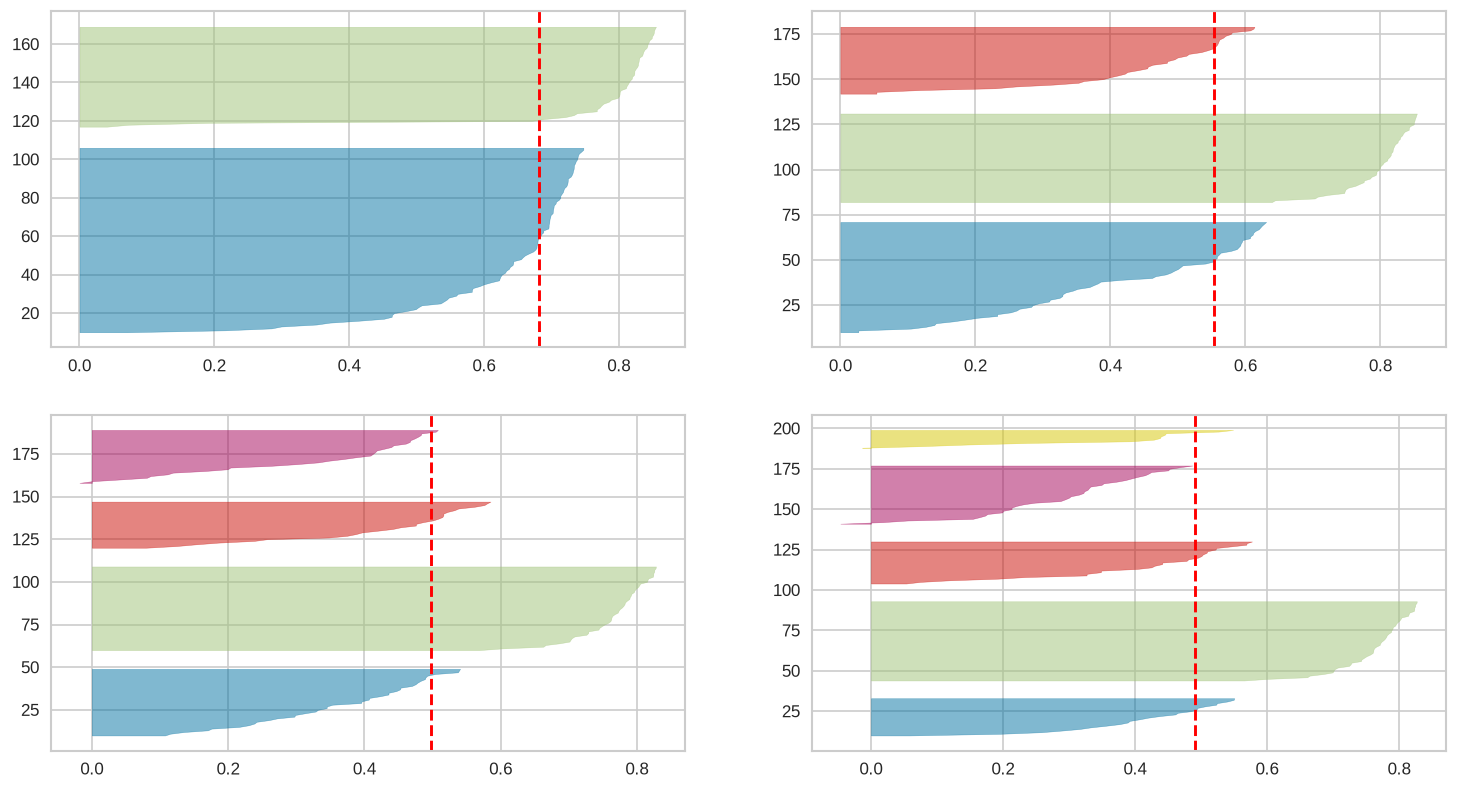

In [19]:
from yellowbrick.cluster import SilhouetteVisualizer
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 2, figsize=(15,8))
scores = []
for i in [2, 3, 4, 5]:
    '''
    Create KMeans instance for different number of clusters
    '''
    km = KMeans(n_clusters=i, init='k-means++', n_init=10, max_iter=100, random_state=42)
    # Fit the KMeans model
    km.fit_predict(X)
    # Calculate Silhoutte Score
    score = silhouette_score(X, km.labels_, metric='euclidean')
    scores.append(score)
    q, mod = divmod(i, 2)
    '''
    Create SilhouetteVisualizer instance with KMeans instance
    Fit the visualizer
    '''
    visualizer = SilhouetteVisualizer(km, colors='yellowbrick', ax=ax[q-1][mod], force_model=True, is_fitted=True)
    visualizer.fit(X)

print({k: round(s, 3) for k, s in zip([2, 3, 4, 5], scores)})

The SSE curve explains why the elbow rule is not a rule. The decrease is steep up to
$k=3$ and then flattens, but it never stops decreasing: at $k$ large enough every point is
its own cluster and the SSE is exactly zero.

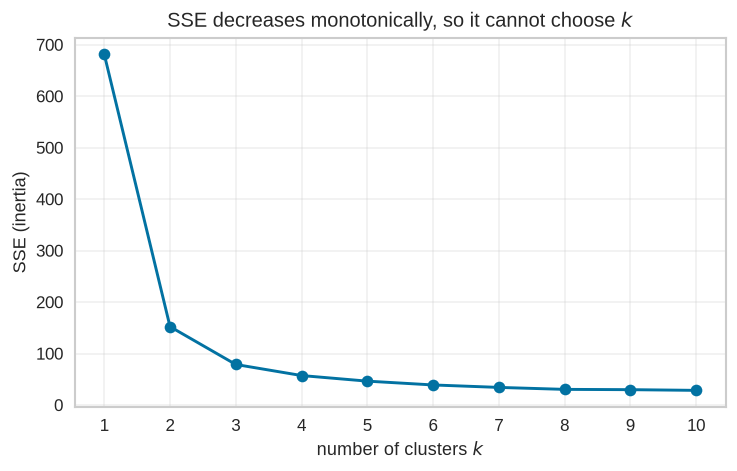

k =  1   SSE =   681.37
k =  2   SSE =   152.35
k =  3   SSE =    78.86
k =  4   SSE =    57.35
k =  5   SSE =    46.47
k =  6   SSE =    39.07
k =  7   SSE =    34.31
k =  8   SSE =    30.48
k =  9   SSE =    29.91
k = 10   SSE =    28.55


In [20]:
ks = range(1, 11)
sse = [KMeans(n_clusters=k, random_state=42).fit(X).inertia_ for k in ks]

plt.figure(figsize=(7, 4))
plt.plot(list(ks), sse, marker="o")
plt.xlabel("number of clusters $k$")
plt.ylabel("SSE (inertia)")
plt.title("SSE decreases monotonically, so it cannot choose $k$")
plt.xticks(list(ks))
plt.grid(alpha=0.3)
plt.show()

for k, value in zip(ks, sse):
    print(f"k = {k:2d}   SSE = {value:8.2f}")

## Choosing the Right Metric

1. Use external measures when ground truth is available
2. Use internal measures when no labels exist
3. Consider multiple metrics together for robust evaluation

Remember that no single metric tells the whole story - different metrics may be more appropriate for different clustering goals.

## The Assignment Problem Behind Maximum Matching

Maximum matching with weights is an instance of the **assignment problem**: given the
$r \times k$ contingency table, choose a one-to-one pairing of rows and columns that
maximises the total weight. For square tables it is solved exactly by the Hungarian
algorithm, which is what `scipy.optimize.linear_sum_assignment` implements; for rectangular
tables the same routine returns an optimal pairing that leaves the surplus rows or columns
unmatched, which is exactly what we want when $r \ne k$.

The same problem appears whenever two sets must be paired under a one-to-one constraint:
students to schools, reviewers to papers, queries to documents, or features to components.
Zaki's chapter 17 develops it for clustering validation; the general treatment is in the
same book ({cite}`zaki2020data`).

### Maximum Weight Matching with `networkx`

The contingency table can also be read as a **bipartite graph**: clusters on one side,
classes on the other, and an edge of weight $n_{ij}$ whenever $n_{ij} > 0$. The maximum
matching score is then the weight of a maximum-weight matching of that graph.

`networkx.algorithms.matching.max_weight_matching` solves the general problem; it is not
restricted to bipartite graphs, so it may use an edge inside one partition if the graph has
one. Here every edge joins a cluster to a class, so the result is a matching of the bipartite
graph. Pass `weight="weight"` explicitly — with the default `weight=None` the edge weights
are ignored and the routine returns a maximum *cardinality* matching instead, which is what
an earlier version of this page did by mistake.

matched pairs and weights:
  C2 - versicolor: 4
  virginica - C3: 50
  C1 - setosa: 30

matched weight = 84   match score = 0.560


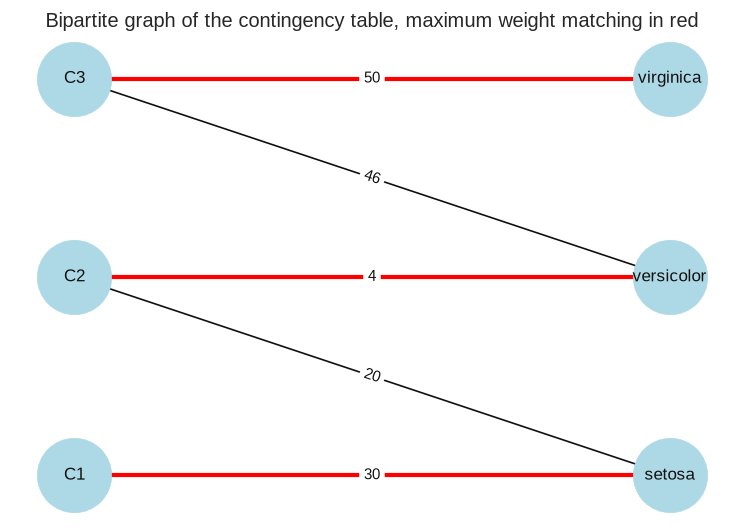

In [21]:
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite

# the contingency table of the bad clustering, as a bipartite graph
table = np.array([[30, 0, 0], [20, 4, 0], [0, 46, 50]])
clusters = ["C1", "C2", "C3"]
classes = ["setosa", "versicolor", "virginica"]

G = nx.Graph()
G.add_nodes_from(clusters, bipartite=0)
G.add_nodes_from(classes, bipartite=1)
for i, cluster in enumerate(clusters):
    for j, cls in enumerate(classes):
        if table[i, j] > 0:
            G.add_edge(cluster, cls, weight=int(table[i, j]))

matching = nx.algorithms.matching.max_weight_matching(G, weight="weight")
total = sum(G[u][v]["weight"] for u, v in matching)

print("matched pairs and weights:")
for u, v in matching:
    print(f"  {u} - {v}: {G[u][v]['weight']}")
print(f"\nmatched weight = {total}   match score = {total / table.sum():.3f}")

pos = {**{n: (0, i) for i, n in enumerate(clusters)},
       **{n: (1, i) for i, n in enumerate(classes)}}
plt.figure(figsize=(6, 4))
nx.draw(G, pos, with_labels=True, node_color="lightblue", node_size=2000, font_size=10)
nx.draw_networkx_edges(G, pos, edgelist=list(matching), width=2.5, edge_color="red")
nx.draw_networkx_edge_labels(G, pos, font_size=9,
                             edge_labels={(u, v): G[u][v]["weight"] for u, v in G.edges})
plt.title("Bipartite graph of the contingency table, maximum weight matching in red")
plt.show()

## Summary

* A clustering needs validation: without labels, "it converged" says nothing about quality.
* External measures start from the $r \times k$ contingency table $n_{ij}$ (row = cluster,
  column = class), computed in $O(n)$.
* Purity is the sum of the row maxima; it is optimistic, because it allows two clusters to
  claim the same class.
* Precision, recall and F add the column view; the maximum matching forces a one-to-one
  pairing and is an assignment problem (`linear_sum_assignment`).
* Pairwise measures count agreements on pairs of points: Jaccard ignores $TN$, Rand counts
  everything and is inflated by $k$, ARI corrects Rand for chance, NMI measures shared
  information but is not corrected.
* Internal measures — silhouette, SSE, gap — use only the data; none of them identifies the
  true number of clusters, and optimising one of them can give the wrong answer.
* Report several measures, and state which question each of them answers.